# Ridge and the Lasso: Coefficients and Error as $\lambda$ Changes

**DSAI 621 — Week 2.** You fit ridge regression and the lasso over a grid of $\lambda$ values
and watch two things change: the coefficients, and the training and test error.

All of the code is written for you: run each cell, read what it does, and change it to try
things out. Short exercises marked **E1**, **E2**, … ask you to stop and look at what you just
made, and answer in words.

In this notebook, as in ISL 6.2, the two methods minimize

$$\text{ridge: } \mathrm{RSS} + \lambda\sum_{j=1}^p\beta_j^2, \qquad \text{lasso: } \mathrm{RSS} + \lambda\sum_{j=1}^p|\beta_j| .$$

scikit-learn calls the tuning parameter `alpha`. For `Ridge`, `alpha` is exactly ISL's $\lambda$.
`Lasso` divides the RSS by $2n$, so its `alpha` is ISL's $\lambda / (2n)$. The two methods'
`alpha` values are on different scales, so compare their *curves*, not their `alpha` numbers.

In [33]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.linear_model import Lasso, LassoCV, LinearRegression, Ridge, RidgeCV
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# random number generator
rng = np.random.default_rng(621)

---
## 1. The data

The diabetes data (Efron et al., 2004) are a standard regression example, and they ship with
scikit-learn. For $n = 442$ patients, they record $p = 10$ baseline predictors: age, sex, body
mass index (`bmi`), blood pressure (`bp`), and six blood serum measurements (`s1`–`s6`). The
response is a measure of disease progression one year later.

We split the data in half, train and test, and standardize the predictors using the training
set's means and standard deviations. Ridge and the lasso penalize every coefficient by the same
amount, so the predictors need to be on a common scale (ISL 6.2.1).

In [34]:
# Load the diabetes dataset and split into training and test sets
diabetes = load_diabetes(as_frame=True, scaled=False)
X, y = diabetes.data, diabetes.target
names = X.columns.tolist()

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.5, random_state=621)

# Scale the data
scaler = StandardScaler().fit(X_tr)
X_tr, X_te = scaler.transform(X_tr), scaler.transform(X_te)

print(f"training set: {X_tr.shape[0]} observations, test set: {X_te.shape[0]}, p = {X_tr.shape[1]}")
X.head()

training set: 221 observations, test set: 221, p = 10


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0


### Least squares first

Ordinary least squares is the $\lambda = 0$ end of both methods, so fit it first as a baseline.

In [35]:
# Define a function to compute the mean squared error (MSE) of a model on given data
def mse(model, X, y):
    return np.mean((y - model.predict(X)) ** 2)

# Fit an ordinary least squares (OLS) model and compute the training and test MSE
ols = LinearRegression().fit(X_tr, y_tr)
print(f"OLS training MSE: {mse(ols, X_tr, y_tr):7.0f}")
print(f"OLS test MSE:     {mse(ols, X_te, y_te):7.0f}")
pd.Series(ols.coef_, index=names).round(1)

OLS training MSE:    2798
OLS test MSE:        3053


age    -2.1
sex   -12.6
bmi    25.6
bp     17.1
s1    -43.2
s2     30.3
s3      6.5
s4     12.9
s5     29.7
s6      4.8
dtype: float64

**E1.** How much larger is the test MSE than the training MSE? With 221 training observations
and 10 predictors, would you expect least squares to overfit badly?

<details>
<summary><strong>E1: show answer</strong></summary>

The test MSE is roughly 10% larger than the training MSE which is not that large of a difference. With $n = 221$ and $p = 10$ there are about 22 observations per coefficient, so least squares has low variance and shouldn't overfit badly.

</details>

---
## 2. Ridge regression

Fit ridge for 81 values of $\lambda$, spaced evenly on a log scale from $10^{-2}$ to $10^{4}$.
For each one, save the coefficients and the training and test MSE.

In [36]:
# Select a range of alpha values for Ridge regression and fit models for each alpha, storing the coefficients and MSEs
ridge_alphas = np.logspace(-2, 4, 81)

ridge_coefs, ridge_train, ridge_test = [], [], []
for a in ridge_alphas:
    model = Ridge(alpha=a).fit(X_tr, y_tr)
    ridge_coefs.append(model.coef_)
    ridge_train.append(mse(model, X_tr, y_tr))
    ridge_test.append(mse(model, X_te, y_te))
ridge_coefs = np.array(ridge_coefs)     # one row per lambda, one column per predictor

### Coefficient paths

The next two functions draw what we just computed, and you'll reuse them for the lasso.
`plot_paths` draws one line per predictor and labels each line at its left end, so you can
identify lines without relying on colour. `plot_errors` draws training and test MSE and marks
the $\lambda$ with the lowest test MSE.

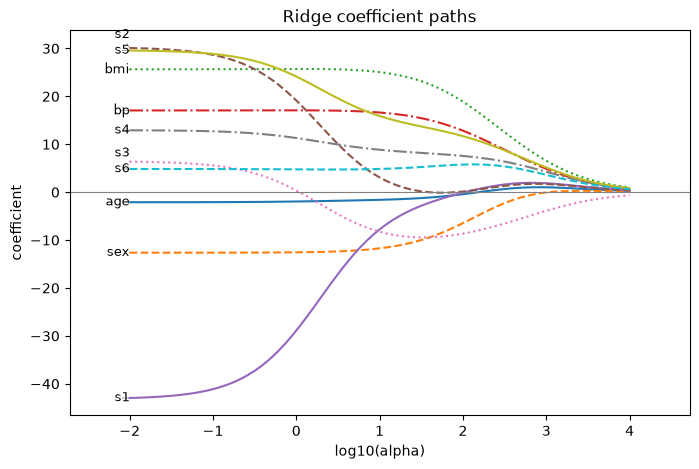

In [37]:
# STYLES is a list of line styles used for plotting the coefficient paths
STYLES = ["-", "--", ":", "-."]

# Define a function to plot the coefficient paths for Ridge regression
def plot_paths(alphas, coefs, names, title, ax=None, label_top=None):
    "One line per coefficient against log10(alpha); label_top labels only the largest few."
    ax = ax or plt.subplots(figsize=(8, 5))[1]
    start = coefs[0]
    show = np.argsort(-np.abs(start))[:label_top] if label_top else range(len(names))
    for j in range(coefs.shape[1]):
        ax.plot(np.log10(alphas), coefs[:, j], STYLES[j % 4], lw=1.5)
    # nudge labels apart so that lines starting close together stay readable
    gap = 0.045 * (coefs.max() - coefs.min())
    ypos = {}
    for j in sorted(show, key=lambda j: start[j]):
        ypos[j] = max(start[j], max(ypos.values(), default=-np.inf) + gap)
    for j in show:
        ax.annotate(names[j], (np.log10(alphas[0]), start[j]), xytext=(np.log10(alphas[0]), ypos[j]),
                    textcoords="data", ha="right", va="center", fontsize=9,
                    arrowprops=dict(arrowstyle="-", color="grey", lw=0.5, shrinkA=8, shrinkB=0))
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(xlabel="log10(alpha)", ylabel="coefficient", title=title)
    ax.margins(x=0.12)
    return ax

# Define a function to plot the training and test MSE against log10(alpha) for Ridge regression
# We use log10(alpha) on the x-axis because the range of alpha values is large and we want to see the behavior across orders of magnitude
def plot_errors(alphas, train, test, title, ax=None):
    "Training and test MSE against log10(alpha); marks the alpha with the lowest test MSE."
    ax = ax or plt.subplots(figsize=(8, 4))[1]
    ax.plot(np.log10(alphas), train, "-", color="black", label="training MSE")
    ax.plot(np.log10(alphas), test, "--", color="tab:red", label="test MSE")
    k = int(np.argmin(test))
    ax.plot(np.log10(alphas[k]), test[k], "v", color="tab:red", ms=9,
            label=f"lowest test MSE: {test[k]:.0f} at alpha = {alphas[k]:.3g}")
    ax.set(xlabel="log10(alpha)", ylabel="MSE", title=title)
    ax.legend()
    return ax

plot_paths(ridge_alphas, ridge_coefs, names, "Ridge coefficient paths")
plt.show()

**E2.** Which coefficients are largest when $\lambda$ is small? Do they match the OLS coefficients
above? Does any coefficient become exactly zero before the right-hand end?

**E3.** Find a coefficient that changes sign as $\lambda$ grows. Look at the serum measurements
`s1`–`s6`: why might correlated predictors behave this way?

<details>
<summary><strong>E2: show answer</strong></summary>

`s1` (about $-43$), then `s2`, `s5` and `bmi`, have the largest coefficients at small $\lambda$. At the left end the ridge coefficients equal the OLS coefficients. None becomes exactly zero; all of them only approach zero as $\lambda \to \infty$.

</details>

<details>
<summary><strong>E3: show answer</strong></summary>

`s1` goes from about $-43$ to slightly positive, and `s3` from about $+6$ to about $-9$ before returning toward zero. `s1` and `s2` are highly correlated (0.90), and so are `s3` and `s4` ($-0.75$). OLS can fit a large positive coefficient on one of a correlated pair and a large negative one on the other, which nearly cancel. Ridge shrinks that cancellation away first, and that can push a coefficient through zero.

</details>

In [38]:
print(pd.DataFrame(X_tr, columns=names)[["s1", "s2", "s3", "s4"]].corr().round(2))

      s1    s2    s3    s4
s1  1.00  0.90  0.01  0.55
s2  0.90  1.00 -0.23  0.66
s3  0.01 -0.23  1.00 -0.75
s4  0.55  0.66 -0.75  1.00


### Training and test error

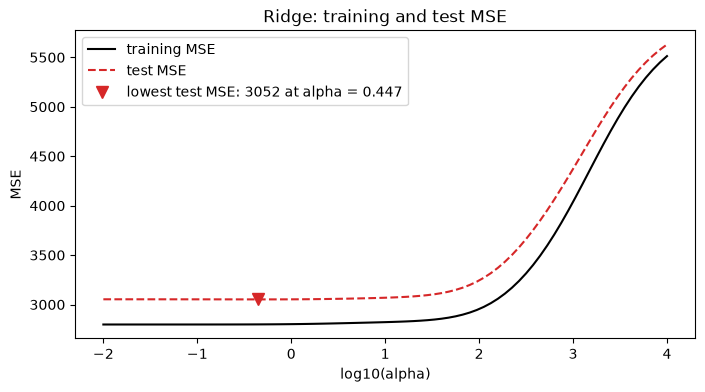

In [39]:
plot_errors(ridge_alphas, ridge_train, ridge_test, "Ridge: training and test MSE")
plt.show()

**E4.** Why does the training MSE only ever go up as $\lambda$ grows? (Hint: what does least
squares minimize?)

**E5.** How much lower is ridge's best test MSE than the OLS test MSE? Given your answer to E1,
is that surprising?

<details>
<summary><strong>E4: show answer</strong></summary>

At $\lambda = 0$ ridge is least squares, which by definition has the smallest possible training RSS. Any $\lambda > 0$ moves the coefficients away from that minimum, so the training MSE can only rise, and it rises further the larger $\lambda$ is. See the app for a visual aid of what is happening as $\lambda$ increases.

</details>

<details>
<summary><strong>E5: show answer</strong></summary>

Barely at all: 3052 against 3053 for OLS. The test curve is flat until $\lambda$ is large and then rises. That isn't surprising. E1 showed OLS has little variance to remove here, so shrinkage has little to gain.

</details>

---
## 3. The lasso

The next cells repeat Section 2 with `Lasso`, on a grid that runs up to the smallest `alpha`
that sets every coefficient to zero. They also record the number of non-zero coefficients for
each `alpha`.

In [40]:
# Select a range of alpha values for Lasso regression and fit models for each alpha, storing the coefficients, MSEs, and number of non-zero coefficients
lasso_alphas = np.logspace(-2, np.log10(50), 81)

lasso_coefs, lasso_train, lasso_test, lasso_nonzero = [], [], [], []
for a in lasso_alphas:
    model = Lasso(alpha=a).fit(X_tr, y_tr)
    lasso_coefs.append(model.coef_)
    lasso_train.append(mse(model, X_tr, y_tr))
    lasso_test.append(mse(model, X_te, y_te))
    lasso_nonzero.append(np.sum(model.coef_ != 0))
lasso_coefs = np.array(lasso_coefs)

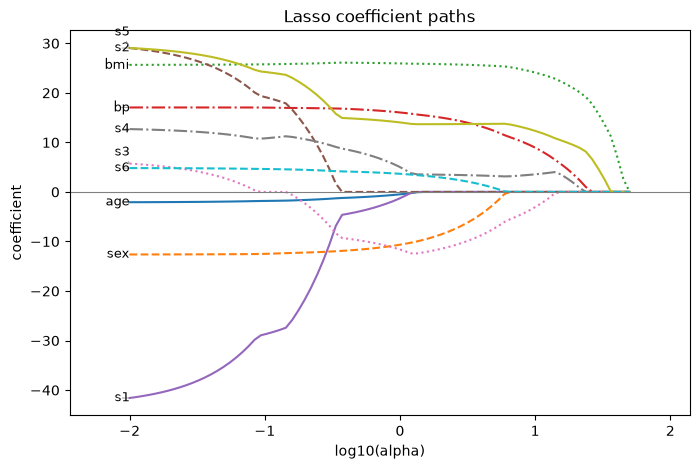

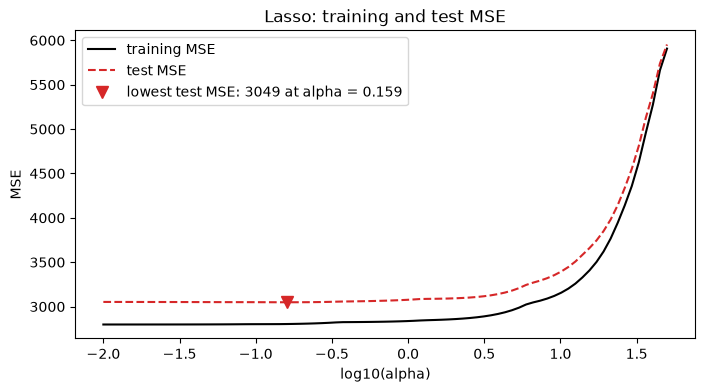

In [41]:
plot_paths(lasso_alphas, lasso_coefs, names, "Lasso coefficient paths")
plt.show()
plot_errors(lasso_alphas, lasso_train, lasso_test, "Lasso: training and test MSE")
plt.show()

**E6.** Read the coefficient paths from right to left, from large $\lambda$ to small. In what
order do the predictors enter the model? Which predictor would the lasso keep if you could only
have one?

**E7.** How does the shape of a lasso path differ from a ridge path? Describe what happens to a
lasso coefficient once it reaches zero.

<details>
<summary><strong>E6: show answer</strong></summary>

`bmi` enters first, then `s5` and `bp`, followed by the others (read the labels on your plot). If you could keep only one predictor, the lasso keeps `bmi`, the last to leave.

</details>

<details>
<summary><strong>E7: show answer</strong></summary>

Lasso paths are piecewise linear with kinks, and each coefficient hits zero at a finite `alpha` and stays exactly zero to the right of that point. Ridge paths are smooth curves that approach zero only as $\lambda \to \infty$.

</details>

In [42]:
k = int(np.argmin(lasso_test))
print(f"lowest test MSE at alpha = {lasso_alphas[k]:.3g}, using {lasso_nonzero[k]} of {len(names)} predictors")
print("dropped:", [n for n, c in zip(names, lasso_coefs[k]) if c == 0])

lowest test MSE at alpha = 0.159, using 10 of 10 predictors
dropped: []


**E8.** Compare the best test MSE of OLS, ridge and the lasso. With $p = 10$ and $n = 221$,
does either method help much?

<details>
<summary><strong>E8: show answer</strong></summary>

They are essentially tied: about 3053 for OLS, 3052 for ridge and 3049 for the lasso, and the lasso's best `alpha` still keeps all 10 predictors. With $p = 10$ and $n = 221$, OLS is already a low-variance fit, so neither penalty helps. A somewhat larger lasso `alpha` would drop several predictors for only a small rise in test MSE: a simpler model at almost no cost.

</details>

---
## 4. Many more predictors

Shrinkage matters most when the model has many predictors relative to $n$. Add every square and
every pairwise product of the 10 predictors (age², bmi × bp, …). `PolynomialFeatures` builds
these columns. We drop sex², because `sex` takes only the values 1 and 2, so sex² is an exact
linear function of `sex`. That leaves $p = 64$ predictors for the same 221 training observations.
We standardize again, because squares and products are on new scales.

In [ ]:
# Fit a polynomial regression model of degree 2
# excluding the square of the "sex" variable, and compute the training and test MSE
poly = PolynomialFeatures(degree=2, include_bias=False).fit(X_tr)
names2 = poly.get_feature_names_out(names).tolist()
keep = [j for j, name in enumerate(names2) if name != "sex^2"]
names2 = [names2[j] for j in keep]
X2_tr, X2_te = poly.transform(X_tr)[:, keep], poly.transform(X_te)[:, keep]
scaler2 = StandardScaler().fit(X2_tr)
X2_tr, X2_te = scaler2.transform(X2_tr), scaler2.transform(X2_te)

# Fit an ordinary least squares (OLS) model on the polynomial features and compute the training and test MSE
ols2 = LinearRegression().fit(X2_tr, y_tr)
print(f"p = {X2_tr.shape[1]}")
print(f"OLS training MSE: {mse(ols2, X2_tr, y_tr):7.0f}")
print(f"OLS test MSE:     {mse(ols2, X2_te, y_te):7.0f}")

p = 64
OLS training MSE:    2078
OLS test MSE:        3909


**E9.** Compare these numbers with the 10-predictor OLS fit in Section 1. Why did the training
MSE go down while the test MSE went up?

<details>
<summary><strong>E9: show answer</strong></summary>

With 64 predictors, least squares has far more flexibility, so it fits the training data more closely (lower training MSE). Much of the extra fit is noise, so the variance goes up and the test MSE rises. This is classic overfitting for an overly complex model.

</details>

The next cells fit ridge and the lasso on the 64 predictors, using the grids below, and plot
the training and test MSE for each method. The lasso needs more iterations to converge at
small `alpha`, so it gets `max_iter=100_000`. (To see the coefficient paths as well, call
`plot_paths` with `label_top=6`, which labels only the six largest of the 64 lines.)

In [ ]:
# Select a range of alpha values for Ridge and Lasso regression on the polynomial features 
# Fit models for each alpha, storing the coefficients and MSEs
ridge2_alphas = np.logspace(-1, 5, 61)
lasso2_alphas = np.logspace(-2, np.log10(50), 61)

ridge2_coefs, ridge2_train, ridge2_test = [], [], []
for a in ridge2_alphas:
    model = Ridge(alpha=a).fit(X2_tr, y_tr)
    ridge2_coefs.append(model.coef_)
    ridge2_train.append(mse(model, X2_tr, y_tr))
    ridge2_test.append(mse(model, X2_te, y_te))
ridge2_coefs = np.array(ridge2_coefs)

lasso2_coefs, lasso2_train, lasso2_test, lasso2_nonzero = [], [], [], []
for a in lasso2_alphas:
    model = Lasso(alpha=a, max_iter=100_000).fit(X2_tr, y_tr)
    lasso2_coefs.append(model.coef_)
    lasso2_train.append(mse(model, X2_tr, y_tr))
    lasso2_test.append(mse(model, X2_te, y_te))
    lasso2_nonzero.append(np.sum(model.coef_ != 0))
lasso2_coefs = np.array(lasso2_coefs)

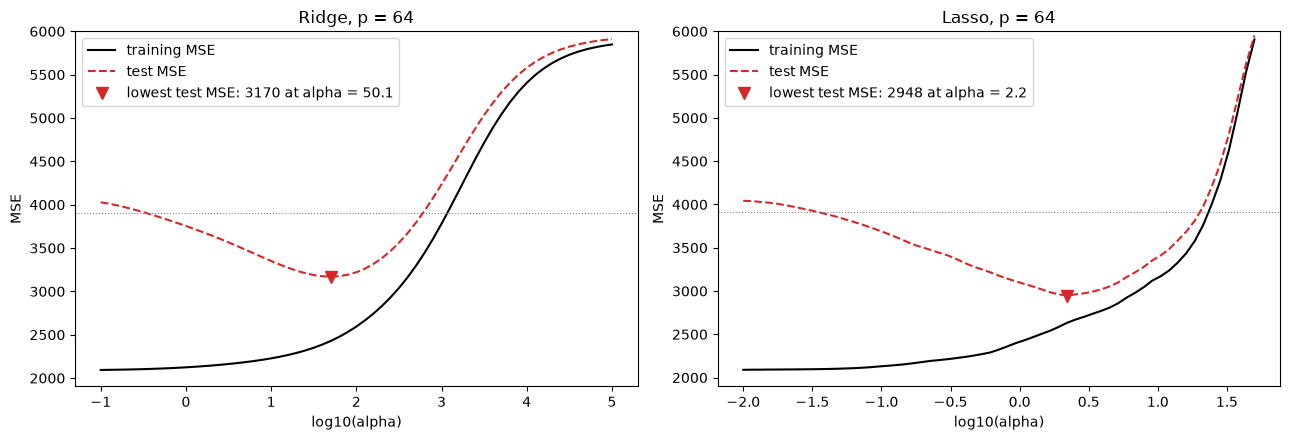

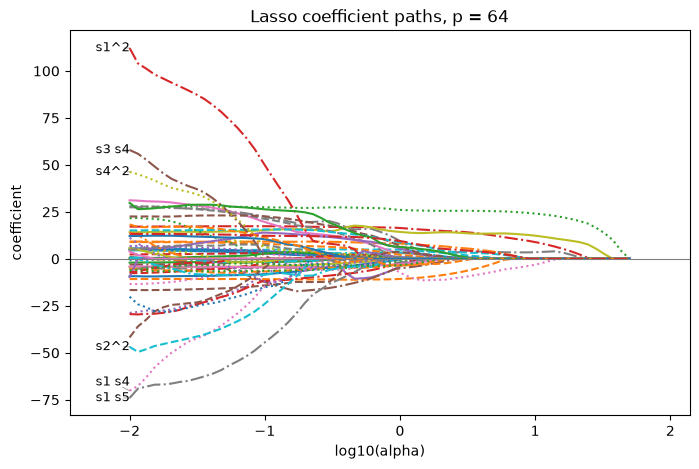

In [45]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
plot_errors(ridge2_alphas, ridge2_train, ridge2_test, "Ridge, p = 64", ax=ax[0])
plot_errors(lasso2_alphas, lasso2_train, lasso2_test, "Lasso, p = 64", ax=ax[1])
for a in ax:
    a.axhline(mse(ols2, X2_te, y_te), color="grey", lw=0.8, ls=":")
    a.set_ylim(top=6000)
plt.tight_layout()
plt.show()

plot_paths(lasso2_alphas, lasso2_coefs, names2, "Lasso coefficient paths, p = 64", label_top=6)
plt.show()

**E10.** Now there's a clear U shape in test MSE. On each plot, which side of the U is high
variance, and which is high bias?

**E11.** The next cell tabulates the best test MSE for OLS, ridge and the lasso with $p = 64$.
How many of the 64 predictors does the lasso use at its best `alpha`? Which ones are they?

<details>
<summary><strong>E10: show answer</strong></summary>

The left side (small `alpha`, close to OLS) is high variance: the training MSE is low and the test MSE high. The right side (large `alpha`, heavy shrinkage) is high bias: both training and test MSE are high, because the model is too simple to capture the signal.

</details>

<details>
<summary><strong>E11: show answer</strong></summary>

OLS has test MSE about 3900; ridge's best is about 3170 and the lasso's about 2950. Both penalized methods beat OLS by a wide margin, and the lasso does best, using only about 20 of the 64 predictors. The main effects `bmi`, `bp` and `s5` are among those kept, together with a handful of squares and interactions. The exact list is in the output above.

</details>

In [ ]:
# Summarize the results of OLS, Ridge, and Lasso regression on the polynomial features, 
# including the best alpha for Ridge and Lasso, and the number of predictors used by Lasso at its best alpha
k = int(np.argmin(lasso2_test))
summary = pd.Series({
    "OLS": mse(ols2, X2_te, y_te),
    "ridge (best alpha)": min(ridge2_test),
    "lasso (best alpha)": min(lasso2_test),
}).round(0)
print(summary, "\n")
print(f"lasso uses {lasso2_nonzero[k]} of 64 predictors at alpha = {lasso2_alphas[k]:.3g}:")
print([n for n, c in zip(names2, lasso2_coefs[k]) if c != 0])

OLS                   3909.0
ridge (best alpha)    3170.0
lasso (best alpha)    2948.0
dtype: float64 

lasso uses 21 of 64 predictors at alpha = 2.2:
['sex', 'bmi', 'bp', 's3', 's4', 's5', 's6', 'age sex', 'age s2', 'age s3', 'age s6', 'sex bmi', 'sex bp', 'sex s3', 'bmi bp', 'bp s5', 's1^2', 's1 s3', 's2 s5', 's5^2', 's6^2']


---
## 5. Choosing $\lambda$ without the test set

So far we picked the best $\lambda$ by looking at the test set. That's cheating: the test set is
then part of the fitting, and its MSE is no longer an honest estimate of how the model does on
new data. In practice we choose $\lambda$ by $K$-fold cross-validation on the training set
(ISL 5.1.3, 6.2.3). `RidgeCV` and `LassoCV` do this for a whole grid of `alpha` values.

In [ ]:
# Use cross-validation to select the best alpha for Ridge regression on the polynomial features and compute the test MSE
ridge_cv = RidgeCV(alphas=ridge2_alphas, cv=10).fit(X2_tr, y_tr)
print(f"ridge: CV chose alpha = {ridge_cv.alpha_:.3g}, test MSE {mse(ridge_cv, X2_te, y_te):.0f}")

ridge: CV chose alpha = 79.4, test MSE 3192


In [ ]:
# Use cross-validation to select the best alpha for Lasso regression on the polynomial features and compute the test MSE
lasso_cv = LassoCV(alphas=lasso2_alphas, cv=10, max_iter=100_000).fit(X2_tr, y_tr)
print(f"lasso: CV chose alpha = {lasso_cv.alpha_:.3g}, test MSE {mse(lasso_cv, X2_te, y_te):.0f}, "
      f"{np.sum(lasso_cv.coef_ != 0)} non-zero coefficients")

lasso: CV chose alpha = 3.88, test MSE 3019, 11 non-zero coefficients


**E12.** How close are the cross-validated choices of `alpha` to the ones that minimized test MSE
in Section 4? How much test MSE did you give up by using cross-validation?

<details>
<summary><strong>E12: show answer</strong></summary>

Cross-validation chose `alpha` within a factor of about two of the test-optimal values (about 79 against 50 for ridge, and 3.9 against 2.2 for the lasso). The test MSE rose by only about 20 for ridge and 70 for the lasso, and the cross-validated lasso keeps only 11 predictors. That small increase is acceptable.

</details>

---
## 6. Wrap-up questions

**Q1.** In your own words, why can the lasso set a coefficient exactly to zero while ridge
can't? (ISL Figure 6.7 may help.)

**Q2.** Suppose a colleague fits the lasso on unstandardized predictors where one predictor is
measured in dollars and another in thousands of dollars. What goes wrong?

**Q3.** In Section 1, shrinkage barely helped; in Section 4 it helped a lot. What changed, and
what does that tell you about when to reach for ridge or the lasso?

<details>
<summary><strong>Q1: show answer</strong></summary>

The lasso's penalty $|\beta_j|$ has a corner at zero. Its slope jumps from $-\lambda$ to $+\lambda$, so whenever the RSS's slope at zero is smaller than $\lambda$ in size, zero is the minimum. Geometrically, the lasso's constraint region is a diamond with corners on the axes, and the RSS contours often touch it first at a corner. Ridge's penalty $\beta_j^2$ is smooth with slope zero at 0, and its constraint region is a disk with no corners, so the minimum is essentially never exactly zero.

</details>

<details>
<summary><strong>Q2: show answer</strong></summary>

The penalty treats a unit change in every coefficient equally, but a coefficient's size depends on the predictor's units. The dollars predictor needs a coefficient 1000 times smaller than the thousands-of-dollars one for the same effect, so it is barely penalized, while the thousands-of-dollars predictor is heavily penalized. The lasso would then keep or drop predictors because of their units rather than their importance. Standardizing puts every predictor on the same scale.

</details>

<details>
<summary><strong>Q3: show answer</strong></summary>

The ratio of predictors to observations changed. With $p = 10$, $n = 221$ OLS had low variance, so there was little for shrinkage to remove. With $p = 64$ the OLS variance is large, and trading a little bias for a big drop in variance pays off. Reach for ridge or the lasso when $p$ is large relative to $n$, or when predictors are highly correlated. Use the lasso when you also want a smaller, more interpretable model.

</details>